# Required packages

In [55]:
import requests
from dotenv import load_dotenv
from newsapi import NewsApiClient
import os
from typing import List, Dict
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage, BaseMessage
from langchain_core.tools import tool
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition

In [56]:
load_dotenv()  # Load environment variables from .env file
def check_if_api_keys_exist() -> bool:
    """
    Check if the required API keys exist in the environment variables.

    Returns:
        bool: True if all required API keys exist, False otherwise.
    """
    required_keys = ["OPENAI_API_KEY", "FREECRYPTO_TOKEN", "NEWSAPI_KEY"]
    return all(key in os.environ and os.environ[key] for key in required_keys)
assert check_if_api_keys_exist(), "API keys are missing. Please set OPENAI_API_KEY, FREECRYPTO_TOKEN, and NEWSAPI_KEY in your environment variables."

In [57]:
# Tools
## Tool to fetch the list of cryptocurrencies
@tool
def crypto_list_tool():
    """"
    Fetch the list of cryptocurrencies using the FreeCryptoAPI.
    Returns:
        dict: A dictionary containing the status and list of cryptocurrencies or an error message.
    """
    url = "https://api.freecryptoapi.com/v1/getCryptoList"
    headers = {
        "Authorization": f"Bearer {os.getenv('FREECRYPTO_TOKEN')}" 
    }
    try:
        response = requests.get(url, headers=headers)
        if response.status_code == 200:
            return {"status": "success", "coins": response.json()["result"]}
        else:
            print(f"Error fetching crypto list: {response.status_code}")
            return {"status": "error", "message": f"Error fetching crypto list: {response.status_code}"}
    except requests.RequestException as e:
        print(f"Error fetching crypto list: {e}")
        return {"status": "error", "message": f"Error fetching crypto list: {e}"}

## Tool to fetch crypto data for a specific symbol
@tool
def crypto_data_tool(symbol: str):
    """
    Fetch crypto data for a specific symbol using the FreeCryptoAPI.
    Kwargs:
        symbol (str): The symbol of the cryptocurrency (e.g., BTC, ETH).
    Returns:
        dict: A dictionary containing the status and data or error message.
    """
    url = f"https://api.freecryptoapi.com/v1/getData?symbol={symbol.upper().strip()}"
    headers = {
        "Authorization": f"Bearer {os.getenv('FREECRYPTO_TOKEN')}"
    }
    try:
        response = requests.get(url, headers=headers)
        if response.status_code == 200:
            return response.json()
        else:
            print(f"Error fetching crypto data for {symbol}: {response.status_code}")
            return {"status": "error", "message": f"Error fetching crypto data for {symbol}: {response.status_code}"}
    except requests.RequestException as e:
        print(f"Error fetching crypto data for {symbol}: {e}")
        return {"status": "error", "message": f"Error fetching crypto data for {symbol}: {e}"}

## Tool to fetch news articles related to a specific query
newsapi = NewsApiClient(api_key=os.getenv('NEWSAPI_KEY'))
@tool
def news_tool(query: str, max_items: int = 5) -> List[Dict]:
    """
    Fetch news articles related to a specific query using the NewsAPI.
    Kwargs:
        query (str): The search query for news articles.
        max_items (int): The maximum number of articles to return. Default is 5.
    Returns:
        List[Dict]: A list of dictionaries containing news article details.
    """
    try:
        all_articles = newsapi.get_everything(q=query, language='en', sort_by='publishedAt', page=1)
        articles = all_articles['articles'] if 'articles' in all_articles else []
        maxed_articles = articles[:max_items]  # Limit the number of articles to max_items
        return [{
            "title": article.get("title"),
            "source": article.get("source", {}).get("name"),
            "url": article.get("url"),
            "publishedAt": article.get("publishedAt")
        } for article in maxed_articles]
    except Exception as e:
        print(f"Error fetching news articles for query '{query}': {e}")
        return []

In [58]:
news_tool.invoke({"query": "Bitcoin", "max_items": 3})  # Example usage

[{'title': 'Binance says billions replaced from hack that FBI blames on North Korea',
  'source': 'CBC News',
  'url': 'https://www.cbc.ca/news/world/binance-hack-north-korea-9.7404502',
  'publishedAt': '2026-10-31T22:54:58Z'},
 {'title': 'Bitcoin’s Fear and Greed Index Fell From 70 to 36 in October. What Happened the Last 3 Times It Dropped This Fast?',
  'source': 'Biztoc.com',
  'url': 'https://biztoc.com/x/e02394a04e8e561c',
  'publishedAt': '2026-10-31T22:53:54Z'},
 {'title': 'FBI links $6B Binance hack to North Korea’s TraderTraitor group',
  'source': 'Crypto Briefing',
  'url': 'https://cryptobriefing.com/fbi-links-6b-binance-hack-to-north-koreas-tradertraitor-group/',
  'publishedAt': '2026-10-31T21:43:30Z'}]

In [59]:
crypto_data_tool.invoke({"symbol": "BTC"})  # Example usage

{'status': 'success',
 'symbols': [{'symbol': 'BTC',
   'last': '78119.99',
   'last_btc': '1',
   'lowest': '77663.58',
   'highest': '78178',
   'date': '2026-11-02 02:31:23',
   'daily_change_percentage': '0.2742524259582',
   'source_exchange': 'binance'}]}

In [60]:
crypto_list_tool.invoke({})  # Example usage

{'status': 'success',
 'coins': [{'id': '1',
   'symbol': 'BTC',
   'name': '',
   'source': 'binance',
   'ohlc_available_from': '2023-01-25',
   'history_available_from': '2016-12-17'},
  {'id': '2',
   'symbol': 'ETH',
   'name': '',
   'source': 'binance',
   'ohlc_available_from': '2023-01-25',
   'history_available_from': '2016-12-18'},
  {'id': '3',
   'symbol': 'LTC',
   'name': '',
   'source': 'binance',
   'ohlc_available_from': '2023-01-25',
   'history_available_from': '2016-12-18'},
  {'id': '4',
   'symbol': 'BNB',
   'name': '',
   'source': 'binance',
   'ohlc_available_from': '2023-01-25',
   'history_available_from': '2016-12-17'},
  {'id': '5',
   'symbol': 'NEO',
   'name': '',
   'source': 'binance',
   'ohlc_available_from': '2023-01-25',
   'history_available_from': '2016-12-18'},
  {'id': '6',
   'symbol': 'GAS',
   'name': '',
   'source': 'binance',
   'ohlc_available_from': '2023-03-17',
   'history_available_from': '2016-12-17'},
  {'id': '7',
   'symbol': 

In [61]:
# tools
tools = [crypto_list_tool, crypto_data_tool, news_tool]
tool_node = ToolNode(tools=tools, name="Crypto Tools")

In [81]:
# System Prompt 
agent_system_prompt = SystemMessage(
    content="""You are a CRYPTO MARKET ANALYST. 
    You have access to the following tools: Crypto List Tool, Crypto Data Tool, and News Tool. 
    
    Dos:
        -Use these tools to provide accurate and up-to-date information about cryptocurrencies. 
        -When responding to user queries, you should first determine which tool(s) to use based on the user's request.
        -Rely on the tools for factual data--no fabricated prices.
        -Provide guidance on citing fields (e.g., priceUsd) and handling errors (e.g., if a symbol is not found).
        -If non-cryptocurrency related queries are asked, politely inform the user that you can only provide information about cryptocurrencies.
        -If asked about what all tool we can use, provide a brief description of each tool and its purpose.
    Donts:
        -Do not provide information that is not supported by the tools.
        -Do not make up data or speculate beyond what the tools provide.
        -Do not ignore tool errors; instead, explain

    Output Format:
        Summary: Provide a concise summary of the cryptocurrency information requested.
        Data: Include relevant data fields from the tools, such as price, market cap, volume, etc.
        What it means: Explain the significance of the data in the context of cryptocurrency analysis.
        Next Steps: Suggest further actions or research based on the information provided.

    """)

In [63]:
llm = ChatOpenAI(model_name="gpt-4o", temperature=0)
llm_with_tools = llm.bind_tools(tools=tools)
def assistant(state: MessagesState):
    ai_message: AIMessage = llm_with_tools.invoke([agent_system_prompt] + state["messages"])
    return {"messages": [ai_message]}

In [64]:
graph_builder = StateGraph(MessagesState)
graph_builder.add_node("assistant", assistant)
graph_builder.add_node("tools", tool_node)

In [65]:
graph_builder.set_entry_point("assistant")
graph_builder.add_conditional_edges("assistant", tools_condition)
graph_builder.add_edge("tools", "assistant")  # Always return to assistant after using tools

In [66]:
graph = graph_builder.compile()
config = {"configurable": {"thread_id": "user_session_1"}}  # Example configuration for thread_id
graph_with_memory = graph_builder.compile(checkpointer=MemorySaver())  # Compile the graph with memory saving capability

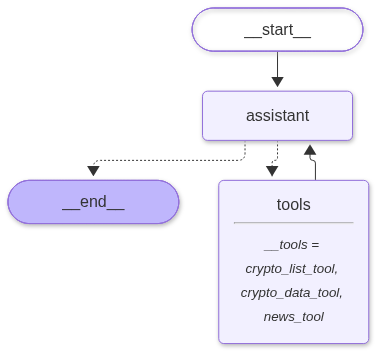

In [67]:
graph

In [68]:
# print("Enter your cryptocurrency query:")
# human_input = input("You: ")
# query = HumanMessage(content=human_input)
# result = graph.invoke({"messages": [query]})
# for message in result["messages"]:
#     message.pretty_print()
# print("AI:\n", result["messages"][-1].content)


In [76]:
def execute(use_memory: bool = False):
    """
    Execute the cryptocurrency query process.

    Args:
        use_memory (bool): If True, use the graph with memory saving capability. Default is False.
    """
    graph_to_use = graph_with_memory if use_memory else graph
    print("Enter your cryptocurrency query:")
    human_input = input("You: ")
    query = HumanMessage(content=human_input)
    if use_memory:
        print("Using graph with memory saving capability.")
    result = graph_to_use.invoke({"messages": [query]}, config=config if use_memory else None)
    for message in result["messages"]:
        message.pretty_print()
    print("AI:\n", result["messages"][-1].content)

In [70]:
execute(use_memory=False)  # Call the execute function with memory saving capability

Enter your cryptocurrency query:
================================ Human Message =================================

what's the latest price of BTC ?
================================== Ai Message ==================================
Tool Calls:
  crypto_data_tool (call_bqTws22X5QiOWpEDCS1qYZSZ)
 Call ID: call_bqTws22X5QiOWpEDCS1qYZSZ
  Args:
    symbol: BTC
================================= Tool Message =================================
Name: crypto_data_tool

{"status": "success", "symbols": [{"symbol": "BTC", "last": "78124", "last_btc": "1", "lowest": "77663.58", "highest": "78178", "date": "2026-11-02 02:31:39", "daily_change_percentage": "0.2793996328668", "source_exchange": "binance"}]}
================================== Ai Message ==================================

Summary: The latest price information for Bitcoin (BTC) has been retrieved successfully.

Data:
- Current Price (USD): $78,124
- Lowest Price (24h): $77,663.58
- Highest Price (24h): $78,178
- Daily Change Percentage: 0.

In [71]:
execute(use_memory=False)  # Call the execute function with memory saving capability

Enter your cryptocurrency query:
================================ Human Message =================================

what's the price you said ?
================================== Ai Message ==================================

I haven't provided any cryptocurrency prices yet. If you would like to know the current price of a specific cryptocurrency, please let me know the symbol (e.g., BTC for Bitcoin, ETH for Ethereum), and I can fetch the latest data for you.
AI:
 I haven't provided any cryptocurrency prices yet. If you would like to know the current price of a specific cryptocurrency, please let me know the symbol (e.g., BTC for Bitcoin, ETH for Ethereum), and I can fetch the latest data for you.


In [77]:
execute(use_memory=True)  # Call the execute function with memory saving capability

Enter your cryptocurrency query:
Using graph with memory saving capability.
================================ Human Message =================================

what's the latest price of BTC ?
================================== Ai Message ==================================
Tool Calls:
  crypto_data_tool (call_WcduO4Br4FPKwchi98PJYgfw)
 Call ID: call_WcduO4Br4FPKwchi98PJYgfw
  Args:
    symbol: BTC
================================= Tool Message =================================
Name: crypto_data_tool

{"status": "success", "symbols": [{"symbol": "BTC", "last": "78366", "last_btc": "1", "lowest": "77663.58", "highest": "78232", "date": "2026-11-02 02:38:49", "daily_change_percentage": "0.59002907722646", "source_exchange": "binance"}]}
================================== Ai Message ==================================

Summary: The latest price information for Bitcoin (BTC) has been retrieved successfully.

Data:
- Current Price (USD): $78,366
- Lowest Price (24h): $77,663.58
- Highest Price 

In [78]:
execute(use_memory=True)  # Call the execute function with memory saving capability

Enter your cryptocurrency query:
Using graph with memory saving capability.
================================ Human Message =================================

what's the latest price of BTC ?
================================== Ai Message ==================================
Tool Calls:
  crypto_data_tool (call_WcduO4Br4FPKwchi98PJYgfw)
 Call ID: call_WcduO4Br4FPKwchi98PJYgfw
  Args:
    symbol: BTC
================================= Tool Message =================================
Name: crypto_data_tool

{"status": "success", "symbols": [{"symbol": "BTC", "last": "78366", "last_btc": "1", "lowest": "77663.58", "highest": "78232", "date": "2026-11-02 02:38:49", "daily_change_percentage": "0.59002907722646", "source_exchange": "binance"}]}
================================== Ai Message ==================================

Summary: The latest price information for Bitcoin (BTC) has been retrieved successfully.

Data:
- Current Price (USD): $78,366
- Lowest Price (24h): $77,663.58
- Highest Price 

In [83]:
print("Welcome to the Cryptocurrency Analyzer!")
while True:
    try:
        user_choice = input("Do you want to enter a cryptocurrency query? (yes/no): ").strip().lower()
        if user_choice == 'yes':
            execute(use_memory=True)
        elif user_choice == 'no':
            print("Exiting the Cryptocurrency Analyzer. Goodbye!")
            break
        else:
            print("Invalid input. Please enter 'yes' or 'no'.")
    except KeyboardInterrupt:
        print("\nExiting the Cryptocurrency Analyzer. Goodbye!")
        break

Welcome to the Cryptocurrency Analyzer!
Invalid input. Please enter 'yes' or 'no'.
Exiting the Cryptocurrency Analyzer. Goodbye!
